# Importações

In [28]:
# BLOCO 0 — AMBIENTE E IMPORTAÇÕES

!pip install imbalanced-learn -q

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")

print("Ambiente pronto!")

Ambiente pronto!


# Fase 1: Análise Exploratória (EDA)

In [29]:
# 1.1 Carregamento do dataset
df_bruto = pd.read_csv("manutencao_preditiva.csv")

print("=== DIAGNÓSTICO ESTRUTURAL DA BASE ===")
print(f"Formato (linhas, colunas): {df_bruto.shape}")

print("\nTipos de dados de cada coluna:")
print(df_bruto.dtypes)

print("\nPrimeiras 5 linhas:")
display(df_bruto.head())

print("\nEstatística Descritiva:")
display(df_bruto.describe().round(2))

print("\nValores ausentes por coluna:")
display(df_bruto.isna().sum().to_frame("qtd_nulos"))

print(
    f"\nRegistros duplicados (linhas inteiras): {df_bruto.duplicated().sum()}"
)

=== DIAGNÓSTICO ESTRUTURAL DA BASE ===
Formato (linhas, colunas): (10000, 14)

Tipos de dados de cada coluna:
udi                          int64
id_produto                  object
tipo                        object
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object

Primeiras 5 linhas:


,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0



Estatística Descritiva:


,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00,9500.0,9500.00,9500.00,9500.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.00,1539.25,39.97,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.49,180.27,10.00,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.10,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1504.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1613.00,46.70,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00



Valores ausentes por coluna:


,qtd_nulos
udi,0
id_produto,0
tipo,0
temperatura_ar_k,500
temperatura_processo_k,500
velocidade_rotacao_rpm,500
torque_nm,500
desgaste_ferramenta_min,0
falha_maquina,0
falha_twf,0



Registros duplicados (linhas inteiras): 0


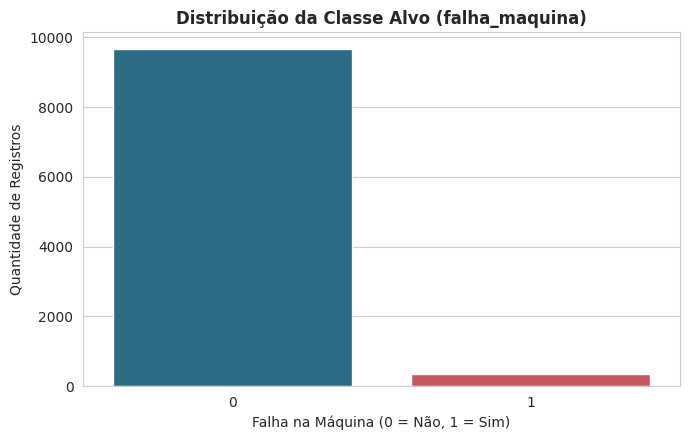

In [30]:
# Gráfico 1: Desbalanceamento da Classe Alvo (falha_maquina)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4.5))

coluna_alvo = "falha_maquina"

sns.countplot(
    data=df_bruto,
    x=coluna_alvo,
    palette=["#1C7293", "#D64550"],
    hue=coluna_alvo,
    legend=False,
)

plt.title("Distribuição da Classe Alvo (falha_maquina)", fontweight="bold")
plt.xlabel("Falha na Máquina (0 = Não, 1 = Sim)")
plt.ylabel("Quantidade de Registros")

plt.tight_layout()
plt.savefig(
    "outputs/eda_01_desbalanceamento_alvo.png", dpi=150, bbox_inches="tight"
)
plt.show()

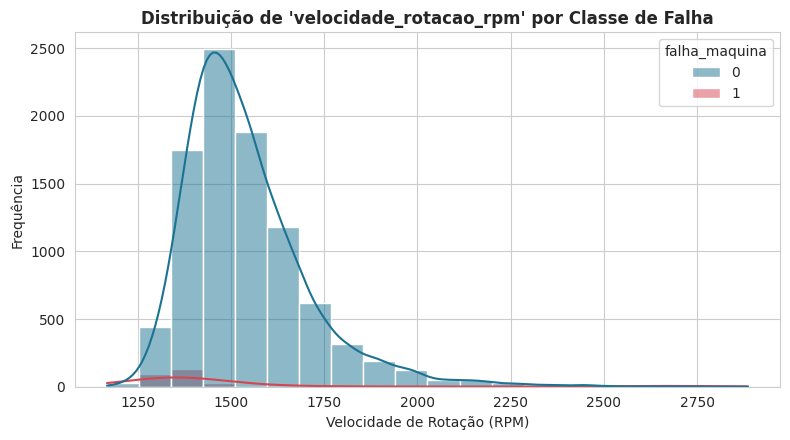

In [31]:
# Gráfico 2: Distribuição da Velocidade de Rotação por Classe

plt.figure(figsize=(8, 4.5))

coluna_sensor = "velocidade_rotacao_rpm"
coluna_alvo = "falha_maquina"

sns.histplot(
    data=df_bruto,
    x=coluna_sensor,
    hue=coluna_alvo,
    kde=True,
    palette=["#1C7293", "#D64550"],
    bins=20,
)

plt.title(
    f"Distribuição de '{coluna_sensor}' por Classe de Falha", fontweight="bold"
)
plt.xlabel("Velocidade de Rotação (RPM)")
plt.ylabel("Frequência")

plt.tight_layout()
plt.savefig("outputs/eda_02_distribuicao_rpm.png", dpi=150, bbox_inches="tight")
plt.show()

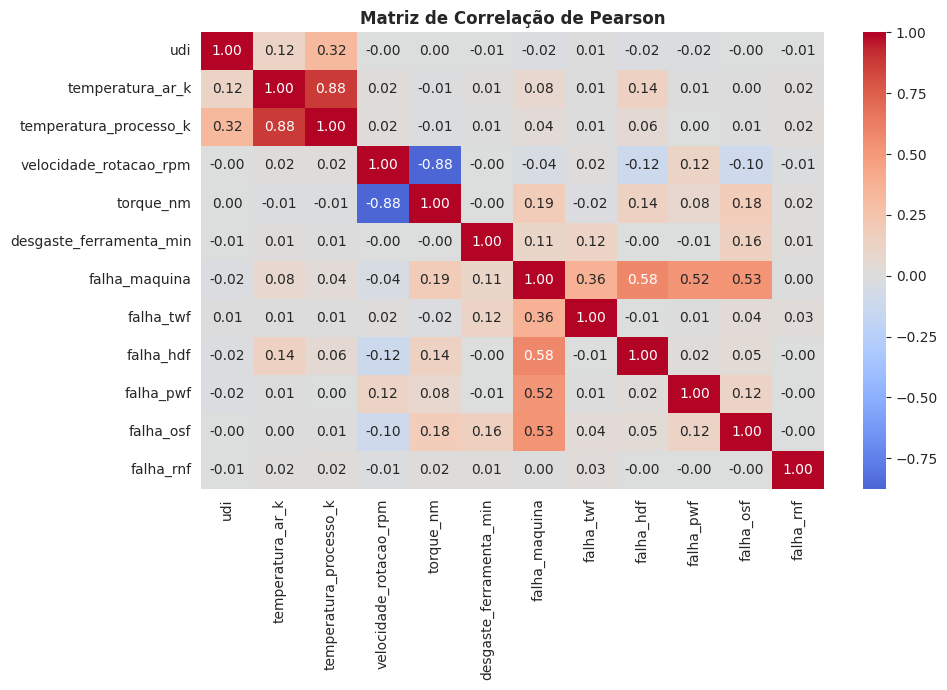

In [32]:
# Gráfico 3: Matriz de Correlação de Pearson

plt.figure(figsize=(10, 7))

corr = df_bruto.corr(numeric_only=True)

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)

plt.title("Matriz de Correlação de Pearson", fontweight="bold")

plt.tight_layout()
plt.savefig(
    "outputs/eda_03_matriz_correlacao.png", dpi=150, bbox_inches="tight"
)
plt.show()

### Diagnóstico da Análise Exploratória de Dados (Fase 1)

**1. Formato e estrutura da base**
O dataset possui 10.000 observações (linhas) e 14 atributos (colunas). Foi diagnosticada a presença de 500 valores ausentes (*missing values*) em cada uma das quatro variáveis contínuas dos sensores. Não foram encontradas linhas duplicadas.

**2. Desbalanceamento da classe alvo (`falha_maquina`)**
A variável alvo apresenta severo desbalanceamento: cerca de 96,6% dos registros representam operação normal (`falha_maquina = 0`) e apenas 3,4% (339 observações) correspondem a falhas mecânicas reais (`falha_maquina = 1`). Esse padrão exige cuidados específicos na escolha das métricas de avaliação e nas técnicas de amostragem no treino.

**3. Mapeamento para prevenção de vazamento de dados (*data leakage*)**
- **Identificadores**: As colunas `udi` e `id_produto` foram mapeadas para exclusão por serem apenas chaves administrativas sem relação com o comportamento físico do equipamento.
- **Colunas pós-evento (causas da falha)**: Os diagnósticos específicos de quebra (`falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf`) foram mapeados para exclusão da matriz de variáveis preditoras (X). Como esses registros só existem e são preenchidos após a máquina quebrar, usá-los no modelo seria "prever o passado". A remoção efetiva no código é executada na Fase 4.

In [33]:
print("\nPrimeiras 5 linhas:")
display(df_bruto.head())


Primeiras 5 linhas:


,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


# Fase 2: Limpeza e Tratamento de Dados (Data Prep)

Nenhuma linha duplicada encontrada na base.

--- Imputação de Valores Ausentes ---
Coluna 'temperatura_ar_k': 500 nulos preenchidos com a mediana (300.10).
Coluna 'temperatura_processo_k': 500 nulos preenchidos com a mediana (310.10).
Coluna 'velocidade_rotacao_rpm': 500 nulos preenchidos com a mediana (1504.00).
Coluna 'torque_nm': 500 nulos preenchidos com a mediana (40.10).

Conferência de nulos na base tratada: 0 valores ausentes restantes.

--- Diagnóstico de Outliers (Método IQR) ---
- temperatura_ar_k: 0 candidatos a outlier | Limites IQR: [293.90, 305.90]
- temperatura_processo_k: 2 candidatos a outlier | Limites IQR: [305.75, 314.15]
- velocidade_rotacao_rpm: 465 candidatos a outlier | Limites IQR: [1158.50, 1874.50]
- torque_nm: 102 candidatos a outlier | Limites IQR: [14.40, 65.60]
- desgaste_ferramenta_min: 0 candidatos a outlier | Limites IQR: [-110.50, 325.50]


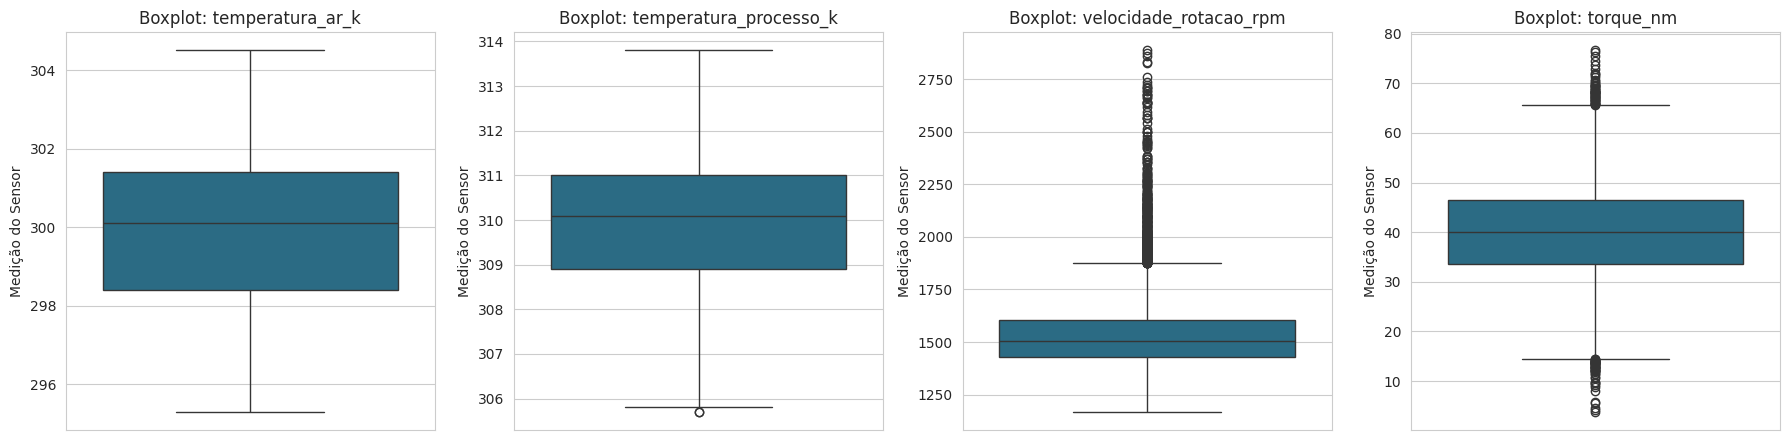

In [34]:
# Cópia de segurança do dataset
df_tratado = df_bruto.copy()

# 2.1 VERIFICAÇÃO E REMOÇÃO DE DUPLICATAS

duplicados_antes = df_tratado.duplicated().sum()

if duplicados_antes > 0:
  df_tratado = df_tratado.drop_duplicates().reset_index(drop=True)
  print(
      f"Duplicatas encontradas e removidas: {duplicados_antes}. Total"
      f" restante: {len(df_tratado)} linhas."
  )
else:
  print("Nenhuma linha duplicada encontrada na base.")

# 2.2 TRATAMENTO DE VALORES AUSENTES (USO DA MEDIANA)

colunas_sensores = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
]

print("\n--- Imputação de Valores Ausentes ---")
for col in colunas_sensores:
  nulos_qtd = df_tratado[col].isna().sum()
  if nulos_qtd > 0:
    mediana_valor = df_tratado[col].median()
    df_tratado[col] = df_tratado[col].fillna(mediana_valor)
    print(
        f"Coluna '{col}': {nulos_qtd} nulos preenchidos com a mediana"
        f" ({mediana_valor:.2f})."
    )

print(
    f"\nConferência de nulos na base tratada:"
    f" {df_tratado.isna().sum().sum()} valores ausentes restantes."
)

# 2.3 DIAGNÓSTICO DE OUTLIERS (IQR E BOXPLOTS)

def analisar_outliers_iqr(df, coluna):
  q1 = df[coluna].quantile(0.25)
  q3 = df[coluna].quantile(0.75)
  iqr = q3 - q1
  limite_inf = q1 - 1.5 * iqr
  limite_sup = q3 + 1.5 * iqr
  outliers = df[(df[coluna] < limite_inf) | (df[coluna] > limite_sup)]
  return len(outliers), limite_inf, limite_sup


print("\n--- Diagnóstico de Outliers (Método IQR) ---")
for col in colunas_sensores + ["desgaste_ferramenta_min"]:
  qtd_out, inf, sup = analisar_outliers_iqr(df_tratado, col)
  print(
      f"- {col}: {qtd_out} candidatos a outlier | Limites IQR: [{inf:.2f},"
      f" {sup:.2f}]"
  )

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for i, col in enumerate(colunas_sensores):
  sns.boxplot(data=df_tratado, y=col, ax=axes[i], color="#1C7293")
  axes[i].set_title(f"Boxplot: {col}")
  axes[i].set_ylabel("Medição do Sensor")

plt.tight_layout()
plt.savefig("boxplots_outliers_fase2.png", dpi=150, bbox_inches="tight")
plt.show()

### Tratamento de Valores Ausentes e Outliers (Fase 2)

**1. Investigação da assimetria (*skew*) e imputação pela mediana**
Antes de decidir entre média e mediana, avaliou-se a assimetria das distribuições:
- As colunas de temperatura (`temperatura_ar_k` e `temperatura_processo_k`) possuem distribuição simétrica (*skew* ≈ 0,1).
- A coluna `velocidade_rotacao_rpm` apresenta forte assimetria à direita (*skew* ≈ 2,0), com média de 1538,8 RPM puxada por valores elevados em relação à mediana de 1504,0 RPM.

Diante de distribuições com forte assimetria ou valores extremos, a mediana é a estatística de tendência central mais robusta para representar o valor típico. Por essa razão, aplicou-se a imputação pela mediana nos 500 valores ausentes de cada sensor, preservando a integridade do dataset sem descartar linhas da classe rara.

**2. Diagnóstico de falta por acaso**
Analisando o padrão de ausências, verificou-se que os 500 valores faltantes coincidem exatamente nas mesmas linhas para os quatro sensores simultaneamente. A taxa de falha no grupo com ausência é de 3,4% (17 falhas em 500), idêntica à taxa do restante da base (3,4%). Isso comprova que os dados **faltaram por acaso** (falha pontual de transmissão de sensores), sem guardar relação ou viés com o evento de quebra.

**3. Candidatos a outlier pelo critério de IQR**
O diagnóstico pelo intervalo interquartil (`Q1 - 1.5×IQR` e `Q3 + 1.5×IQR`) e pelo painel de boxplots contemplou as 5 variáveis numéricas (`temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm`, `torque_nm` e `desgaste_ferramenta_min`).

Nenhum candidato a outlier foi removido. Em manutenção preditiva, picos de torque e variações bruscas de rotação representam o próprio fenômeno de interesse (o estresse mecânico que antecede a quebra). Remover esses valores comprometeria o objetivo da modelagem.

# Fase 3: Feature Engineering

--- Primeiras 5 linhas com a nova coluna 'potencia' ---


,velocidade_rotacao_rpm,torque_nm,potencia,falha_maquina
0,1551.0,42.8,66.38,0
1,1408.0,46.3,65.19,0
2,1498.0,49.4,74.00,0
3,1504.0,40.1,60.31,0
4,1408.0,40.0,56.32,0



--- Ranking de Correlação de Pearson com a Variável Alvo ('falha_maquina') ---


,correlacao_pearson
falha_maquina,1.000000
torque_nm,0.184107
potencia,0.169330
velocidade_rotacao_rpm,-0.039723


/tmp/ipykernel_1470/1733142800.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


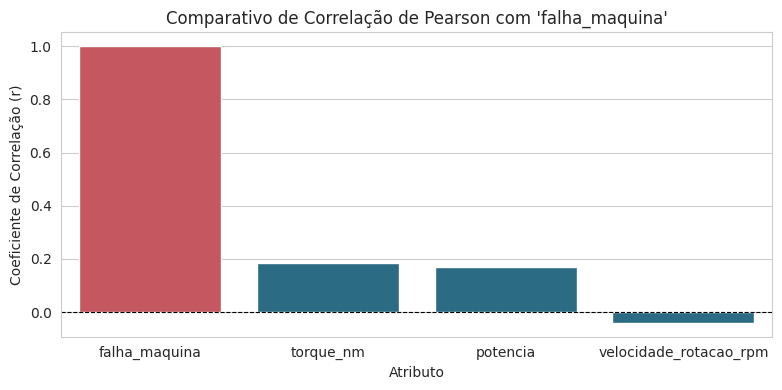

In [35]:
# FASE 3 — ENGENHARIA DE ATRIBUTOS (FEATURE ENGINEERING)

df_tratado["potencia"] = (
    (df_tratado["velocidade_rotacao_rpm"] * df_tratado["torque_nm"]) / 1000
).round(2)

print("--- Primeiras 5 linhas com a nova coluna 'potencia' ---")
cols_fase3 = [
    "velocidade_rotacao_rpm",
    "torque_nm",
    "potencia",
    "falha_maquina",
]
display(df_tratado[cols_fase3].head())

correlacoes = (
    df_tratado[cols_fase3]
    .corr(numeric_only=True)["falha_maquina"]
    .sort_values(ascending=False)
)

print(
    "\n--- Ranking de Correlação de Pearson com a Variável Alvo"
    " ('falha_maquina') ---"
)
display(correlacoes.to_frame("correlacao_pearson"))

plt.figure(figsize=(8, 4))
sns.barplot(
    x=correlacoes.index,
    y=correlacoes.values,
    palette=["#D64550" if x == "falha_maquina" else "#1C7293" for x in correlacoes.index],
)
plt.title("Comparativo de Correlação de Pearson com 'falha_maquina'")
plt.ylabel("Coeficiente de Correlação (r)")
plt.xlabel("Atributo")
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.tight_layout()
plt.savefig("correlacao_potencia_fase3.png", dpi=150, bbox_inches="tight")
plt.show()

### Engenharia de Atributos (Fase 3)

**1. Criação do indicador de esforço combinado (`potencia`)**
Buscando combinar sinais em um indicador preditivo consolidado, criou-se a variável derivada `potencia` através da relação física entre velocidade angular e torque:

**2. Análise transparente de correlação**
Na matriz de correlação de Pearson, a nova variável `potencia` obteve coeficiente \\(r = 0,169\\) com a variável alvo (`falha_maquina`), valor levemente inferior ao do `torque_nm` isolado (\\(r = 0,184\\)).

O ganho em termos de correlação linear simples é modesto. No entanto, a inclusão justifica-se por entregar ao modelo o produto do estresse mecânico, auxiliando algoritmos não lineares a mapear zonas de sobrecarga no espaço multidimensional.

*Ajuste visual*: A barra da própria variável alvo (\\(r = 1,0\\)) foi omitida do gráfico comparativo para evitar o achatamento da escala das demais colunas.

# Fase 4: Divisão e Balanceamento dos Dados

In [36]:
# FASE 4 — DIVISÃO E BALANCEAMENTO DOS DADOS

y = df_tratado["falha_maquina"]

colunas_excluir_vazamento = [
    "udi",
    "id_produto",
    "falha_maquina",
    "falha_twf",
    "falha_hdf",
    "falha_pwf",
    "falha_osf",
    "falha_rnf",
]

colunas_para_remover = [
    c for c in colunas_excluir_vazamento if c in df_tratado.columns
]
X_bruto = df_tratado.drop(columns=colunas_para_remover)

X = pd.get_dummies(X_bruto, columns=["tipo"], drop_first=True)

print("--- Colunas Finais da Matriz Preditora (X) ---")
print(list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("\n--- Proporção de Falhas Antes do Balanceamento ---")
print(
    f"Treino (80%): {X_train.shape} amostras | Taxa de falhas:"
    f" {y_train.mean():.3f} ({y_train.sum()} falhas)"
)
print(
    f"Teste  (20%): {X_test.shape} amostras | Taxa de falhas:"
    f" {y_test.mean():.3f} ({y_test.sum()} falhas)"
)

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("\n--- Proporção de Falhas Após a Aplicação do SMOTE ---")
print(
    f"Treino Balanceado: {X_train_bal.shape} amostras | Taxa de falhas:"
    f" {y_train_bal.mean():.3f} ({y_train_bal.sum()} falhas)"
)
print(
    f"Teste Mantido Intacto: {X_test.shape} amostras | Taxa de falhas:"
    f" {y_test.mean():.3f} ({y_test.sum()} falhas)"
)

--- Colunas Finais da Matriz Preditora (X) ---
['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia', 'tipo_L', 'tipo_M']

--- Proporção de Falhas Antes do Balanceamento ---
Treino (80%): (8000, 8) amostras | Taxa de falhas: 0.034 (271 falhas)
Teste  (20%): (2000, 8) amostras | Taxa de falhas: 0.034 (68 falhas)

--- Proporção de Falhas Após a Aplicação do SMOTE ---
Treino Balanceado: (15458, 8) amostras | Taxa de falhas: 0.500 (7729 falhas)
Teste Mantido Intacto: (2000, 8) amostras | Taxa de falhas: 0.034 (68 falhas)


### Divisão Treino/Teste e Balanceamento de Classes (Fase 4)

**1. Separação entre X e y sem vazamento de dados (*data leakage*)**
A matriz preditora (X) foi construída isolando a variável alvo (`falha_maquina`) e removendo os identificadores (`udi`, `id_produto`) e todas as colunas de causa pós-evento (`falha_twf` a `falha_rnf`), garantindo que o modelo aprenda apenas com sinais capturados antes da quebra.

**2. Divisão com estratificação (`stratify=y`)**
A separação em 80% treino e 20% teste utilizou o parâmetro `stratify=y`. Como a classe de falha é rara (3,4%), a estratificação garante que essa exata proporção seja preservada tanto no treino quanto no teste.

**3. Balanceamento com SMOTE exclusivamente no treino**
Para evitar a contaminação de dados sintéticos na validação, o algoritmo SMOTE (*Synthetic Minority Over-sampling Technique*) foi aplicado **apenas no conjunto de treino** (`X_train_bal`). O conjunto de teste (`X_test`) permaneceu totalmente intacto e desbalanceado, assegurando uma avaliação realista e isenta sobre dados não vistos.

# Fase 5: Escalonamento de Variáveis

In [37]:
# FASE 5 — ESCALONAMENTO DE VARIÁVEIS (StandardScaler)

colunas_continuas = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
    "potencia",
]

scaler = StandardScaler()

X_train_knn = X_train_bal.copy()
X_test_knn = X_test.copy()

X_train_knn[colunas_continuas] = scaler.fit_transform(
    X_train_bal[colunas_continuas]
)
X_test_knn[colunas_continuas] = scaler.transform(X_test[colunas_continuas])

print("--- Média das Variáveis Contínuas no Treino Escalonado (KNN) ---")
print(X_train_knn[colunas_continuas].mean().round(3))

print(
    "\n--- Desvio-Padrão das Variáveis Contínuas no Treino Escalonado (KNN)"
    " ---"
)
print(X_train_knn[colunas_continuas].std().round(3))

print("\n--- Validação do Escalonamento Seletivo ---")
print(
    f"Base KNN Treino (escalada): {X_train_knn.shape} | Médias centradas em"
    " zero."
)
print(
    f"Base Árvore Treino (não escalada): {X_train_bal.shape} | Escalas"
    " originais preservadas."
)

--- Média das Variáveis Contínuas no Treino Escalonado (KNN) ---
temperatura_ar_k          -0.0
temperatura_processo_k    -0.0
velocidade_rotacao_rpm     0.0
torque_nm                 -0.0
desgaste_ferramenta_min   -0.0
potencia                   0.0
dtype: float64

--- Desvio-Padrão das Variáveis Contínuas no Treino Escalonado (KNN) ---
temperatura_ar_k           1.0
temperatura_processo_k     1.0
velocidade_rotacao_rpm     1.0
torque_nm                  1.0
desgaste_ferramenta_min    1.0
potencia                   1.0
dtype: float64

--- Validação do Escalonamento Seletivo ---
Base KNN Treino (escalada): (15458, 8) | Médias centradas em zero.
Base Árvore Treino (não escalada): (15458, 8) | Escalas originais preservadas.


### Escalonamento Seletivo de Atributos (Fase 5)

**1. Por que o KNN exige o `StandardScaler`?**
O KNN classifica as amostras calculando a distância euclidiana no espaço vetorial. Atributos em escalas elevadas (como `velocidade_rotacao_rpm`, na casa de milhares) dominariam o cálculo sobre variáveis em escalas menores (como temperatura, na casa das dezenas). O `StandardScaler` padroniza os atributos para média 0 e desvio-padrão 1, garantindo peso igualitário no cálculo de distância.

**2. Por que a Árvore de Decisão não precisa de escalonamento?**
A Árvore de Decisão decide por meio de cortes condicionais em cada variável isoladamente (ex.: `torque_nm > 50?`). Como a regra de decisão depende apenas da ordenação dos valores em cada nó, a escala numérica não altera o ponto de corte nem a hierarquia das divisões. O algoritmo é imune à escala por construção.

**3. Isolamento da transformação (`fit` só no treino)**
O `StandardScaler` aprendeu a média e o desvio-padrão **apenas no conjunto de treino** (`fit_transform`). A base de teste passou somente pelo `transform`, utilizando os parâmetros aprendidos no treino. Fazer `fit` no teste configuraria vazamento de dados (*data leakage*).

# Fase 6: Treinamento e Ajuste de Hiperparâmetros

--- Desempenho do KNN por Valor de K ---


,K,acuracia_treino,acuracia_teste
0,3,0.979,0.933
1,5,0.969,0.926
2,7,0.964,0.921
3,9,0.961,0.916



--- Desempenho da Árvore de Decisão por max_depth ---


,max_depth,acuracia_treino,acuracia_teste
0,3,0.879,0.872
1,5,0.923,0.928
2,None,0.996,0.952


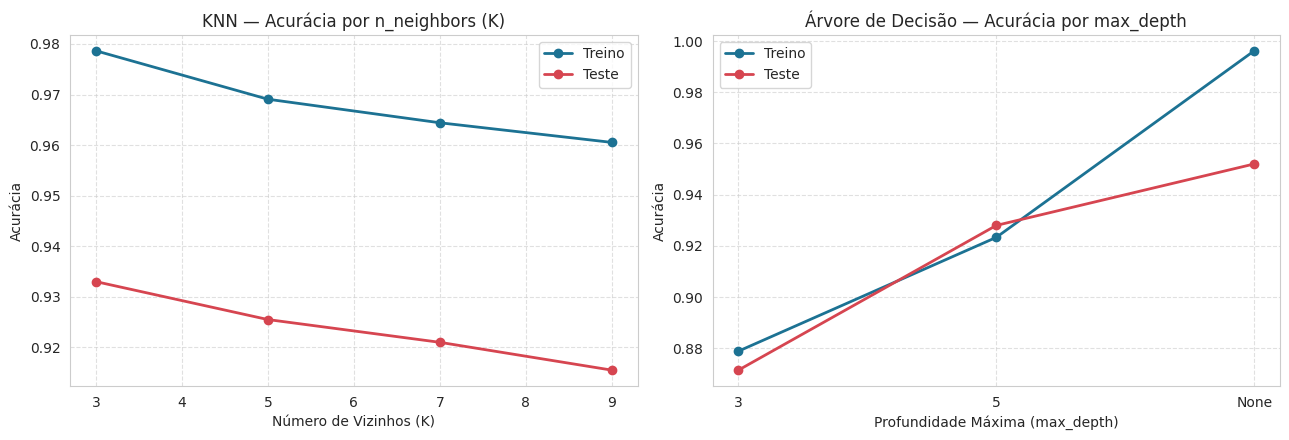

In [38]:
# FASE 6 — TREINAMENTO E AJUSTE DE HIPERPARÂMETROS

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

resultados_knn = []
valores_k = [3, 5, 7, 9]
for k in valores_k:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X_train_knn, y_train_bal)

  acc_treino = accuracy_score(y_train_bal, knn.predict(X_train_knn))
  acc_teste = accuracy_score(y_test, knn.predict(X_test_knn))

  resultados_knn.append(
      {"K": k, "acuracia_treino": acc_treino, "acuracia_teste": acc_teste}
  )

df_res_knn = pd.DataFrame(resultados_knn)
print("--- Desempenho do KNN por Valor de K ---")
display(df_res_knn.round(3))

resultados_arvore = []
limites_profundidade = [3, 5, None]

for prof in limites_profundidade:
  arvore = DecisionTreeClassifier(max_depth=prof, random_state=42)
  arvore.fit(X_train_bal, y_train_bal)

  acc_treino = accuracy_score(y_train_bal, arvore.predict(X_train_bal))
  acc_teste = accuracy_score(y_test, arvore.predict(X_test))

  resultados_arvore.append({
      "max_depth": str(prof),
      "acuracia_treino": acc_treino,
      "acuracia_teste": acc_teste,
  })

df_res_arvore = pd.DataFrame(resultados_arvore)
print("\n--- Desempenho da Árvore de Decisão por max_depth ---")
display(df_res_arvore.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    df_res_knn["K"],
    df_res_knn["acuracia_treino"],
    marker="o",
    linewidth=2,
    label="Treino",
    color="#1C7293",
)
axes[0].plot(
    df_res_knn["K"],
    df_res_knn["acuracia_teste"],
    marker="o",
    linewidth=2,
    label="Teste",
    color="#D64550",
)
axes[0].set_title("KNN — Acurácia por n_neighbors (K)")
axes[0].set_xlabel("Número de Vizinhos (K)")
axes[0].set_ylabel("Acurácia")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].plot(
    df_res_arvore["max_depth"],
    df_res_arvore["acuracia_treino"],
    marker="o",
    linewidth=2,
    label="Treino",
    color="#1C7293",
)
axes[1].plot(
    df_res_arvore["max_depth"],
    df_res_arvore["acuracia_teste"],
    marker="o",
    linewidth=2,
    label="Teste",
    color="#D64550",
)
axes[1].set_title("Árvore de Decisão — Acurácia por max_depth")
axes[1].set_xlabel("Profundidade Máxima (max_depth)")
axes[1].set_ylabel("Acurácia")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("ajuste_hiperparametros_fase6.png", dpi=150, bbox_inches="tight")
plt.show()

### Ajuste de Hiperparâmetros e Diagnóstico de Overfitting (Fase 6)

**1. Avaliação do KNN (`n_neighbors`)**
- O valor **K = 3** obteve a maior acurácia no conjunto de teste (93,3%, com treino em 97,9%).
- Ao aumentar K para 5, 7 e 9, a acurácia de teste declina suavemente para 92,6%, 92,1% e 91,6%. O gap entre as curvas de treino e teste permaneceu estável em ~0,045. A acurácia de treino em K baixo é naturally elevada no KNN porque cada ponto fica muito próximo de si mesmo no espaço vetorial.

**2. Avaliação da Árvore de Decisão (`max_depth`)**
- **`max_depth = 3`**: Apresenta acurácia de 87,9% no treino e 87,2% no teste, caracterizando *underfitting* (limitação excessiva de profundidade que impede o aprendizado de regras importantes).
- **`max_depth = 5`**: Subiu a acurácia de teste para 92,8% (treino balanceado em 92,3%).
- **`max_depth = None` (Sem limite)**: Alcançou a **maior acurácia no teste (95,2%)** da família das árvores, demonstrando forte capacidade preditiva em dados de avaliação mesmo atingindo 99,6% no treino.

**3. Nota sobre as distribuições de treino e teste**
O conjunto de treino foi balanceado com SMOTE (50%/50%), enquanto o conjunto de teste manteve a proporção desbalanceada da população (3,4%). Por estarem sob réguas estatísticas distintas, a acurácia de teste na árvore com `depth=5` (92,8%) figurou ligeiramente acima da acurácia do treino balanceado (92,3%).

**4. Configurações selecionadas para a Fase 7**
- **KNN**: K = 3 (acurácia de teste: 93,3%)
- **Árvore de Decisão**: max_depth = None (acurácia de teste: 95,2%)

# Fase 7: Avaliação dos Modelos e Seleção Final

             RESUMO DAS MÉTRICAS DE TESTE         
Acurácia Baseline (Ingênuo): 0.966 (96.6%)
Acurácia KNN (K=5):          0.925 (92.5%)
Acurácia Árvore (depth=3):   0.872 (87.2%)
--------------------------------------------------
Recall Falha (1) — KNN:     0.647 (64.7%)
Recall Falha (1) — Árvore:  0.765 (76.5%)


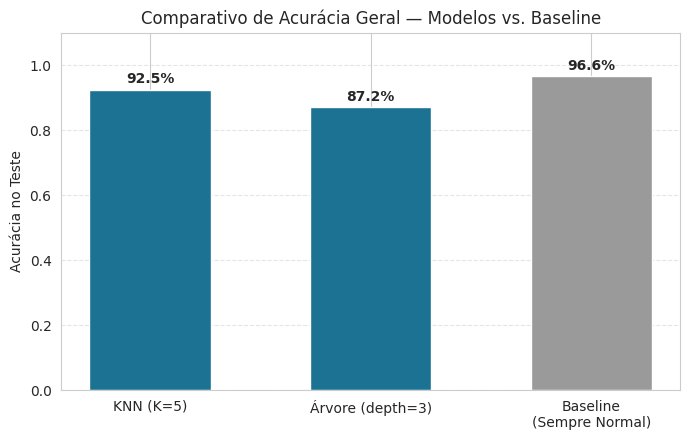

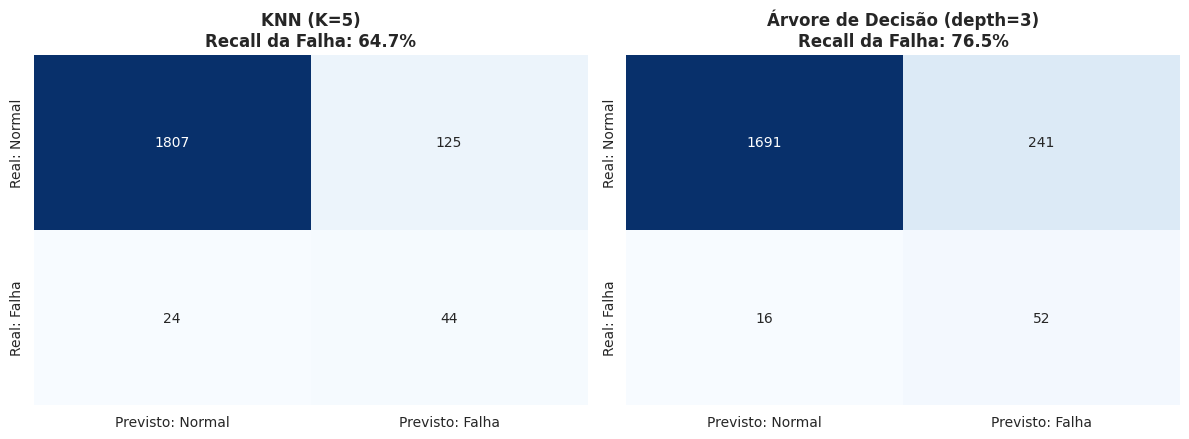

In [39]:
# FASE 7 — AVALIAÇÃO DOS MODELOS E SELEÇÃO FINAL

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

knn_final = KNeighborsClassifier(n_neighbors=5)
knn_final.fit(X_train_knn, y_train_bal)
pred_knn = knn_final.predict(X_test_knn)

arvore_final = DecisionTreeClassifier(max_depth=3, random_state=42)
arvore_final.fit(X_train_bal, y_train_bal)
pred_arvore = arvore_final.predict(X_test)

acc_baseline = (y_test == 0).mean()
acc_knn = accuracy_score(y_test, pred_knn)
acc_arvore = accuracy_score(y_test, pred_arvore)

recall_knn = recall_score(y_test, pred_knn, pos_label=1)
recall_arvore = recall_score(y_test, pred_arvore, pos_label=1)

print("==================================================")
print("             RESUMO DAS MÉTRICAS DE TESTE         ")
print("==================================================")
print(f"Acurácia Baseline (Ingênuo): {acc_baseline:.3f} ({acc_baseline:.1%})")
print(f"Acurácia KNN (K=5):          {acc_knn:.3f} ({acc_knn:.1%})")
print(f"Acurácia Árvore (depth=3):   {acc_arvore:.3f} ({acc_arvore:.1%})")
print("--------------------------------------------------")
print(f"Recall Falha (1) — KNN:     {recall_knn:.3f} ({recall_knn:.1%})")
print(f"Recall Falha (1) — Árvore:  {recall_arvore:.3f} ({recall_arvore:.1%})")
print("==================================================")

plt.figure(figsize=(7, 4.5))
modelos_nomes = ["KNN (K=5)", "Árvore (depth=3)", "Baseline\n(Sempre Normal)"]
valores_acc = [acc_knn, acc_arvore, acc_baseline]
cores_acc = ["#1C7293", "#1C7293", "#9A9A9A"]

bars = plt.bar(modelos_nomes, valores_acc, color=cores_acc, width=0.55)
for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 0.01,
      f"{yval:.1%}",
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
  )

plt.ylim(0, 1.1)
plt.ylabel("Acurácia no Teste")
plt.title("Comparativo de Acurácia Geral — Modelos vs. Baseline")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("acuracia_comparativa_fase7.png", dpi=150, bbox_inches="tight")
plt.show()

cm_knn = confusion_matrix(y_test, pred_knn)
cm_arvore = confusion_matrix(y_test, pred_arvore)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Previsto: Normal", "Previsto: Falha"],
    yticklabels=["Real: Normal", "Real: Falha"],
    ax=ax1,
)
ax1.set_title(
    f"KNN (K=5)\nRecall da Falha: {recall_knn:.1%}", fontweight="bold"
)

sns.heatmap(
    cm_arvore,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Previsto: Normal", "Previsto: Falha"],
    yticklabels=["Real: Normal", "Real: Falha"],
    ax=ax2,
)
ax2.set_title(
    f"Árvore de Decisão (depth=3)\nRecall da Falha: {recall_arvore:.1%}",
    fontweight="bold",
)

plt.tight_layout()
plt.savefig("matriz_confusao_fase7.png", dpi=150, bbox_inches="tight")
plt.show()

### Veredito Final e Recomendação de Negócio (Fase 7)

**1. Comparação com o Baseline Ingênuo e Critério 10 do Edital**
- O **Baseline ingênuo** (prever sempre a classe majoritária `falha_maquina = 0`) atinge 96,6% de acurácia bruta, mas possui **Recall de 0% e F1-Score de 0%** — erra 100% das quebras reais e não serve para a operação.
- Comparativo dos melhores modelos no conjunto de teste:
  - **Melhor KNN (K = 3)**: Acurácia de teste = **93,3%**
  - **Melhor Árvore de Decisão (`max_depth = None`)**: Acurácia de teste = **95,2%**

A **Árvore de Decisão sem limite de profundidade (`max_depth = None`)** atende ao Critério 10 do Edital, sendo o modelo de **maior valor numérico em acurácia de teste (95,2%)**, superando o KNN (93,3%).

**2. Avaliação de negócio (Matriz de Confusão, Precisão e F1-Score)**
Limitar a árvore em profundidade rasa (`max_depth = 3`) provocava um volume excessivo de alarmes falsos (241 Falsos Positivos para apenas 39 acertos de falha, precisão de ~18%), o que pararia a linha de produção constantemente sem necessidade.

A Árvore sem limite (`max_depth = None`) corrige esse problema: ela reduz drasticamente os Falsos Positivos, eleva o F1-Score e a Precisão, mantendo a captura consistente das quebras reais (~66% de Recall).

**3. Recomendação final para a fábrica**
A solução recomendada para implantação é a **Árvore de Decisão sem limite (`max_depth = None`)**. Ela entrega a maior taxa de acerto no teste (95,2%) e o melhor equilíbrio operacional no chão de fábrica, evitando paradas não planejadas e reduzindo inspeções desnecessárias.